## Task 1 — Data Import & Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

# In Google Colab upload the CSV first (or mount Drive) and change the path if needed
PATH = "social_media_engagement_5000.csv"
df = pd.read_csv(PATH)
raw = df.copy()          # untouched copy, used later for before/after comparisons
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.00,Female,Brazil,496713,image,fitness,"7,011.00",354.00,"1,157.00",5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.19
1,10860,33.00,Male,Brazil,157326,reel,food,"11,750.00","2,606.00","1,807.00",5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.20
2,86820,32.00,Female,UK,109864,text,food,"4,862.00",344.00,955.00,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.14
3,64886,51.00,Other,France,848877,text,fitness,"5,350.00","1,083.00","1,049.00",229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.11
4,16265,34.00,Other,UK,449706,image,fitness,"12,682.00","2,735.00","1,300.00",4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.78


In [3]:
print("Shape:", df.shape)
print()
print(df.dtypes)

Shape: (5000, 19)

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


**Observations**
- `posted_at` was read as text (`dd-mm-yyyy`) → must become a real datetime.
- `age`, `likes`, `comments`, `shares` are floats only because they contain missing values (NaN).
- `is_verified` is already boolean; `hashtags` is a space-separated string.

In [4]:
# Convert the date column. The format is day-month-year, so we state it explicitly
# (otherwise pandas can silently swap day and month).
df["posted_at"] = pd.to_datetime(df["posted_at"], format="%d-%m-%Y", errors="coerce")
print("Unparseable dates:", df["posted_at"].isna().sum())
print("Date range:", df["posted_at"].min().date(), "->", df["posted_at"].max().date())
print(df["posted_at"].dtype)

Unparseable dates: 0
Date range: 2022-01-01 -> 2023-12-31
datetime64[ns]


## Task 2 — Data Cleaning

### 2.1 Missing values

In [5]:
missing = pd.DataFrame({"missing": df.isnull().sum(), "pct": (df.isna().mean() * 100).round(2)})
missing[missing["missing"] > 0]

,missing,pct
age,150,3.00
gender,150,3.00
likes,150,3.00
comments,150,3.00
shares,150,3.00
sentiment,150,3.00


Six columns have exactly 150 (3 %) missing values each: `age`, `gender`, `likes`, `comments`, `shares`, `sentiment`.
Dropping those rows would throw away data, so I impute instead (first I show what `dropna()` would cost).

In [6]:
print("Rows if we used dropna():", len(df.dropna()), "of", len(df))   # shows why dropping is wasteful
print("Rows with at least one NaN:", df.isna().any(axis=1).sum())

Rows if we used dropna(): 4162 of 5000
Rows with at least one NaN: 838


In [7]:
# age: numeric & roughly symmetric -> median
df["age"] = df["age"].fillna(df["age"].median())

# gender: categorical -> mode
df["gender"] = df["gender"].fillna(df["gender"].mode()[0])

# likes / comments / shares: counts differ by post type, so fill with the MEDIAN OF THE SAME post_type
for col in ["likes", "comments", "shares"]:
    df[col] = df[col].fillna(df.groupby("post_type")[col].transform("median"))

# sentiment: imputing a sentiment would invent information, so keep an explicit 'unknown' label
df["sentiment"] = df["sentiment"].fillna("unknown")

print("Remaining missing values:", df.isna().sum().sum())

Remaining missing values: 0


> **Why not forward/backward fill?** `ffill()`/`bfill()` copy the neighbouring row's value. Rows here are not ordered in time or by user, so a neighbour is no more informative than a random row. Median/mode is the defensible choice.

### 2.2 Duplicates

In [8]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated post_id values:", df["post_id"].duplicated().sum())
df[df["post_id"].duplicated(keep=False)].sort_values("post_id").head(6)[["user_id","post_id","posted_at","post_type","likes"]]

Fully duplicated rows: 0
Duplicated post_id values: 9


,user_id,post_id,posted_at,post_type,likes
3941,73811,301157,2023-10-03,video,"13,388.00"
3336,82127,301157,2022-09-09,video,"9,512.00"
2153,59104,444417,2023-03-02,image,"16,786.00"
4993,82779,444417,2023-08-10,text,"19,664.00"
2117,69189,448492,2022-10-12,text,790.00
693,15713,448492,2023-10-21,image,"12,383.00"


There are **no fully duplicated rows**. 9 `post_id` values repeat, but each pair has a different user, date and metrics, so these are ID collisions (the IDs look randomly generated), **not duplicate records**. I keep them. `drop_duplicates()` is still run so the step is documented:

In [9]:
before = len(df)
df = df.drop_duplicates()
print("Rows removed:", before - len(df))

Rows removed: 0


### 2.3 Data formatting & standardisation

In [10]:
# Standardise text categories: strip spaces, consistent case
for col in ["gender", "country", "post_type", "post_category", "device_type", "sentiment"]:
    df[col] = df[col].astype(str).str.strip()

df["gender"] = df["gender"].str.title()          # Male / Female / Other
df["sentiment"] = df["sentiment"].str.lower()    # positive / neutral / negative / unknown
df["post_type"] = df["post_type"].str.lower()
df["post_category"] = df["post_category"].str.lower()
df["device_type"] = df["device_type"].str.lower()

# Fix data types: counts and age are whole numbers, not floats
for col in ["age", "likes", "comments", "shares"]:
    df[col] = df[col].round().astype("int64")

for col in ["gender", "country", "post_type", "post_category", "device_type", "sentiment"]:
    print(col, "->", sorted(df[col].unique()))

gender -> ['Female', 'Male', 'Other']
country -> ['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'India', 'Japan', 'UAE', 'UK', 'USA']
post_type -> ['image', 'reel', 'text', 'video']
post_category -> ['education', 'fashion', 'fitness', 'food', 'lifestyle', 'music', 'tech', 'travel']
device_type -> ['desktop', 'mobile', 'tablet']
sentiment -> ['negative', 'neutral', 'positive', 'unknown']


### 2.4 Unrealistic values in likes / comments / shares

In [11]:
metrics = ["likes", "comments", "shares", "watch_time_sec", "impression_count", "follower_count", "age"]
print("Negative values per column:\n", (df[metrics] < 0).sum(), "\n")
print("Age range:", df["age"].min(), "-", df["age"].max())

# A post cannot get more likes than impressions: a like requires someone to have seen the post
bad = df["likes"] > df["impression_count"]
print("Rows where likes > impressions:", bad.sum(), f"({bad.mean()*100:.1f}%)")
df.loc[bad, ["likes", "comments", "shares", "impression_count"]].head()

Negative values per column:
 likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
follower_count      0
age                 0
dtype: int64 

Age range: 13 - 64
Rows where likes > impressions: 464 (9.3%)


,likes,comments,shares,impression_count
4,12682,2735,1300,6019
11,19856,1723,905,1816
13,15700,1434,1886,389
14,13850,586,650,4797
19,9252,1542,139,2453


In [12]:
# Each metric is counted per viewer, so each one individually must be <= impressions
# (one viewer can like AND comment AND share, so the three do not have to sum to <= impressions)
for c in ["likes", "comments", "shares"]:
    print(c, "> impressions:", (df[c] > df["impression_count"]).sum())

likes > impressions: 464
comments > impressions: 65
shares > impressions: 55


In [13]:
# Fix: flag the rows (so the change is traceable) and cap each metric at impression_count.
df["capped_flag"] = (df[["likes", "comments", "shares"]].gt(df["impression_count"], axis=0)).any(axis=1)
for c in ["likes", "comments", "shares"]:
    df[c] = np.minimum(df[c], df["impression_count"])
print("Rows capped:", df["capped_flag"].sum())
print("Rows still impossible:", (df[["likes", "comments", "shares"]].gt(df["impression_count"], axis=0)).any(axis=1).sum())

Rows capped: 467
Rows still impossible: 0


In [14]:
print(df["engagement_rate"].describe(percentiles=[.5, .9, .95, .99]))
cap = df["engagement_rate"].quantile(0.99)
df["engagement_rate_w"] = df["engagement_rate"].clip(upper=cap)
print("\n99th percentile cap:", round(cap, 2), "| rows capped:", (df["engagement_rate"] > cap).sum())

count   5,000.00
mean        0.96
std         5.32
min         0.01
50%         0.25
90%         1.20
95%         2.33
99%        13.67
max       191.50
Name: engagement_rate, dtype: float64

99th percentile cap: 13.67 | rows capped: 50


### 2.5 Feature cleaning — hashtags & sentiment

In [15]:
# Hashtags: normalise to lowercase, split on whitespace and count
df["hashtags"] = df["hashtags"].fillna("").str.lower().str.strip()
df["hashtag_count"] = df["hashtags"].str.split().str.len()
print(df["hashtag_count"].value_counts().sort_index())
df[["hashtags", "hashtag_count"]].head()

hashtag_count
1    1655
2    1697
3    1648
Name: count, dtype: int64


,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


In [16]:
# Sentiment: confirm labels are clean and see how many are unknown
print(df["sentiment"].value_counts())

sentiment
positive    2363
neutral     1527
negative     960
unknown      150
Name: count, dtype: int64


## Task 3 — Data Exploration using Pandas

In [17]:
display(df.head())
display(df.tail())
print("Shape:", df.shape)
print("Columns:", list(df.columns))

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,capped_flag,engagement_rate_w,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.19,False,0.19,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.20,False,0.20,1
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.14,False,0.14,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.11,False,0.11,3
4,16265,34,Other,UK,449706,image,fitness,6019,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.78,True,2.78,1


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,capped_flag,engagement_rate_w,hashtag_count
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.47,False,0.47,2
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.62,False,0.62,2
4997,67021,63,Female,USA,273595,text,travel,13487,1526,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.68,False,0.68,2
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.22,False,0.22,3
4999,73400,54,Other,Japan,712252,text,travel,14234,503,1798,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.20,True,1.20,3


Shape: (5000, 22)
Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'capped_flag', 'engagement_rate_w', 'hashtag_count']


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            5000 non-null   int64         
 1   age                5000 non-null   int64         
 2   gender             5000 non-null   object        
 3   country            5000 non-null   object        
 4   post_id            5000 non-null   int64         
 5   post_type          5000 non-null   object        
 6   post_category      5000 non-null   object        
 7   likes              5000 non-null   int64         
 8   comments           5000 non-null   int64         
 9   shares             5000 non-null   int64         
 10  watch_time_sec     5000 non-null   int64         
 11  impression_count   5000 non-null   int64         
 12  posted_at          5000 non-null   datetime64[ns]
 13  follower_count     5000 non-null   int64         
 14  is_verif

In [19]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
user_id,"5,000.00","54,561.89","10,055.00","32,309.50","54,374.50","77,180.50","99,963.00","26,090.37"
age,"5,000.00",38.44,13.00,26.00,38.00,51.00,64.00,14.69
post_id,"5,000.00","548,042.91","100,068.00","322,543.50","548,077.50","771,574.50","999,455.00","260,646.96"
likes,"5,000.00","9,457.06",10.00,"4,561.25","9,382.00","14,155.75","19,998.00","5,667.34"
comments,"5,000.00","1,489.61",0.00,765.00,"1,508.50","2,227.25","2,999.00",857.37
shares,"5,000.00",995.58,0.00,501.00,"1,010.00","1,470.00","1,999.00",570.23
watch_time_sec,"5,000.00","4,014.50",0.00,"2,017.75","4,034.50","6,020.25","7,998.00","2,308.10"
impression_count,"5,000.00","50,013.73",105.00,"24,988.25","49,934.50","74,662.25","99,995.00","28,844.94"
posted_at,5000,2022-12-28 13:21:30.240000,2022-01-01 00:00:00,2022-07-03 18:00:00,2022-12-27 00:00:00,2023-06-28 00:00:00,2023-12-31 00:00:00,NaN
follower_count,"5,000.00","393,698.22",87.00,"194,480.00","388,982.00","589,744.25","799,533.00","230,927.88"


In [20]:
df.describe(include=["object", "string"]).T

,count,unique,top,freq
gender,5000,3,Male,1849
country,5000,10,India,535
post_type,5000,4,reel,1283
post_category,5000,8,fitness,675
device_type,5000,3,mobile,1684
sentiment,5000,4,positive,2363
hashtags,5000,761,#tech,201


In [21]:
for col in ["gender", "country", "post_type", "post_category", "device_type", "sentiment"]:
    print(f"--- {col} (nunique = {df[col].nunique()}) ---")
    print(df[col].value_counts().to_string(), "\n")
print("unique post types:", df["post_type"].unique())

--- gender (nunique = 3) ---
gender
Male      1849
Other     1581
Female    1570 

--- country (nunique = 10) ---
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472 

--- post_type (nunique = 4) ---
post_type
reel     1283
image    1247
text     1245
video    1225 

--- post_category (nunique = 8) ---
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593 

--- device_type (nunique = 3) ---
device_type
mobile     1684
tablet     1658
desktop    1658 

--- sentiment (nunique = 4) ---
sentiment
positive    2363
neutral     1527
negative     960
unknown      150 

unique post types: ['image' 'reel' 'text' 'video']


In [22]:
numeric_cols = ["age", "likes", "comments", "shares", "watch_time_sec",
                "impression_count", "follower_count", "engagement_rate"]
corr = df[numeric_cols].corr()
corr

,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
age,1.00,-0.03,-0.01,0.01,0.01,0.01,-0.02,0.01
likes,-0.03,1.00,0.01,0.02,0.00,0.19,-0.03,-0.15
comments,-0.01,0.01,1.00,0.02,-0.02,0.02,-0.01,-0.10
shares,0.01,0.02,0.02,1.00,0.02,0.02,-0.01,-0.08
watch_time_sec,0.01,0.00,-0.02,0.02,1.00,-0.00,0.00,-0.00
impression_count,0.01,0.19,0.02,0.02,-0.00,1.00,-0.02,-0.23
follower_count,-0.02,-0.03,-0.01,-0.01,0.00,-0.02,1.00,0.00
engagement_rate,0.01,-0.15,-0.10,-0.08,-0.00,-0.23,0.00,1.00


In [23]:
# groupby summaries
print(df.groupby("post_type")[["likes", "comments", "shares"]].mean().round(0))
print()
print(df.groupby("country")["impression_count"].mean().round(0).sort_values(ascending=False))

             likes  comments   shares
post_type                            
image     9,450.00  1,514.00 1,013.00
reel      9,510.00  1,496.00   976.00
text      9,413.00  1,486.00 1,003.00
video     9,454.00  1,462.00   990.00

country
India       52,462.00
France      51,728.00
USA         51,264.00
UK          51,119.00
Japan       49,616.00
Brazil      49,193.00
UAE         48,928.00
Canada      48,703.00
Germany     48,605.00
Australia   48,346.00
Name: impression_count, dtype: float64


In [24]:
# slicing / indexing / filtering examples
print(df.loc[df["is_verified"] & (df["follower_count"] > 700_000), ["user_id", "country", "follower_count", "likes"]].head())
print()
print(df.iloc[0:5, 0:6])
print()
top10 = df.nlargest(10, "likes")[["post_id", "post_type", "post_category", "likes"]]
top10

     user_id  country  follower_count  likes
38     79092  Germany          780044   8146
291    56214       UK          751871  14798
504    67458   Canada          743690  14265
549    57280      USA          744401  10568
754    24489    India          755597   1672

   user_id  age  gender country  post_id post_type
0    25795   43  Female  Brazil   496713     image
1    10860   33    Male  Brazil   157326      reel
2    86820   32  Female      UK   109864      text
3    64886   51   Other  France   848877      text
4    16265   34   Other      UK   449706     image



,post_id,post_type,post_category,likes
3985,850959,text,fashion,19998
1544,753479,image,education,19996
1496,589982,video,fashion,19995
287,938147,reel,music,19994
2415,771366,text,music,19992
1632,641620,image,food,19986
1605,716963,text,fashion,19981
3402,897872,video,lifestyle,19981
2284,126576,text,travel,19979
3656,919432,video,travel,19979


## Task 4 — Data Wrangling

In [25]:
# New fields
df["engagement_score"] = df["likes"] + df["comments"] + df["shares"]            # total interactions
df["weighted_score"]   = df["likes"] + 2 * df["comments"] + 3 * df["shares"]    # comments/shares need more effort
df["engagement_per_impression"] = df["engagement_score"] / df["impression_count"] * 100

# log transforms (log1p handles zeros) - these metrics are right-skewed
df["log_followers"]   = np.log1p(df["follower_count"])
df["log_impressions"] = np.log1p(df["impression_count"])
df["log_engagement_rate"] = np.log1p(df["engagement_rate"])

# Date features
df["year"]      = df["posted_at"].dt.year
df["month"]     = df["posted_at"].dt.month
df["month_name"]= df["posted_at"].dt.month_name()
df["weekday"]   = df["posted_at"].dt.day_name()
df["is_weekend"]= df["posted_at"].dt.dayofweek >= 5

# Age group buckets
df["age_group"] = pd.cut(df["age"], bins=[17, 24, 34, 44, 54, 64],
                         labels=["18-24", "25-34", "35-44", "45-54", "55-64"])
df[["engagement_score", "weighted_score", "engagement_per_impression", "log_followers", "hashtag_count", "age_group", "weekday"]].head()

,engagement_score,weighted_score,engagement_per_impression,log_followers,hashtag_count,age_group,weekday
0,8522,11190,19.09,11.31,3,35-44,Saturday
1,16163,22383,20.15,8.69,1,25-34,Friday
2,6161,8415,13.73,13.13,1,25-34,Sunday
3,7482,10663,10.62,13.08,3,45-54,Sunday
4,10054,15389,167.04,12.86,1,25-34,Tuesday


In [26]:
# merge: build a country-level lookup table and join it back to the post-level data
country_avg = (df.groupby("country", as_index=False)
                 .agg(country_avg_er=("engagement_rate", "median"),
                      country_avg_score=("engagement_score", "mean")))
df = df.merge(country_avg, on="country", how="left")
df[["country", "engagement_rate", "country_avg_er", "country_avg_score"]].head()

,country,engagement_rate,country_avg_er,country_avg_score
0,Brazil,0.19,0.25,"11,775.51"
1,Brazil,0.20,0.25,"11,775.51"
2,UK,0.14,0.24,"11,816.76"
3,France,0.11,0.24,"12,071.76"
4,UK,2.78,0.24,"11,816.76"


In [27]:
# concat: stack summaries of the three categorical groupings into one table
parts = []
for g in ["post_type", "country", "sentiment"]:
    t = (df.groupby(g)
           .agg(posts=("post_id", "count"),
                avg_likes=("likes", "mean"),
                avg_engagement_score=("engagement_score", "mean"),
                median_engagement_rate=("engagement_rate", "median"),
                avg_impressions=("impression_count", "mean"))
           .reset_index().rename(columns={g: "group"}))
    t.insert(0, "grouped_by", g)
    parts.append(t)
summary = pd.concat(parts, ignore_index=True)
summary.round(2)

,grouped_by,group,posts,avg_likes,avg_engagement_score,median_engagement_rate,avg_impressions
0,post_type,image,1247,"9,450.37","11,978.06",0.26,"49,727.42"
1,post_type,reel,1283,"9,509.55","11,981.17",0.25,"50,462.60"
2,post_type,text,1245,"9,412.96","11,901.91",0.25,"49,987.22"
3,post_type,video,1225,"9,453.69","11,906.00",0.25,"49,862.01"
4,country,Australia,493,"9,438.89","11,920.36",0.27,"48,346.38"
5,country,Brazil,504,"9,302.21","11,775.51",0.25,"49,193.17"
6,country,Canada,513,"9,425.09","11,952.57",0.26,"48,703.15"
7,country,France,496,"9,569.47","12,071.76",0.24,"51,727.67"
8,country,Germany,490,"9,632.10","12,132.08",0.27,"48,605.41"
9,country,India,535,"9,505.21","12,020.29",0.25,"52,462.39"


> I use the **median** engagement rate for rankings because the column is heavily right-skewed (skewness ≈ 19): a handful of posts with tiny impression counts produce rates over 100 and would otherwise decide the ranking.

## Task 5 — Statistical Analysis

In [28]:
stat_cols = ["likes", "comments", "shares", "watch_time_sec", "engagement_rate", "follower_count"]
rows = {}
for c in stat_cols:
    x = df[c]
    arr = x.to_numpy()                               # NumPy array
    rows[c] = {
        "mean": x.mean(), "median": x.median(), "mode": x.mode().iloc[0],
        "std": x.std(), "variance": x.var(),
        "min": x.min(), "p25": np.percentile(arr, 25), "p50": np.percentile(arr, 50),
        "p75": np.percentile(arr, 75), "p90": np.percentile(arr, 90), "p95": np.percentile(arr, 95),
        "max": x.max(), "skewness": x.skew(), "kurtosis": x.kurt(),
    }
stats_df = pd.DataFrame(rows).T
stats_df

,mean,median,mode,std,variance,min,p25,p50,p75,p90,p95,max,skewness,kurtosis
likes,"9,457.06","9,382.00","9,984.00","5,667.34","32,118,697.94",10.00,"4,561.25","9,382.00","14,155.75","17,565.10","18,892.10","19,998.00",0.12,-1.12
comments,"1,489.61","1,508.50","1,518.00",857.37,"735,088.67",0.00,765.00,"1,508.50","2,227.25","2,689.00","2,858.00","2,999.00",0.02,-1.15
shares,995.58,"1,010.00","1,041.00",570.23,"325,159.93",0.00,501.00,"1,010.00","1,470.00","1,790.00","1,897.00","1,999.00",-0.00,-1.15
watch_time_sec,"4,014.50","4,034.50",916.00,"2,308.10","5,327,309.26",0.00,"2,017.75","4,034.50","6,020.25","7,212.10","7,577.05","7,998.00",-0.02,-1.20
engagement_rate,0.96,0.25,0.01,5.32,28.28,0.01,0.15,0.25,0.50,1.20,2.33,191.50,18.78,482.99
follower_count,"393,698.22","388,982.00","497,502.00","230,927.88","53,327,687,855.63",87.00,"194,480.00","388,982.00","589,744.25","717,755.90","760,174.35","799,533.00",0.04,-1.19


In [29]:
# Are group differences real or just noise? (non-parametric Kruskal-Wallis test, since engagement_rate is skewed)
def kw(col, by):
    groups = [g[col].values for _, g in df.groupby(by)]
    h, p = stats.kruskal(*groups)
    return p

tests = []
for by in ["post_type", "post_category", "country", "device_type", "sentiment", "age_group"]:
    tests.append({"grouping": by,
                  "p (engagement_rate)": kw("engagement_rate", by),
                  "p (engagement_score)": kw("engagement_score", by),
                  "p (watch_time_sec)": kw("watch_time_sec", by),
                  "p (impressions)": kw("impression_count", by)})
pd.DataFrame(tests).set_index("grouping").round(4)

,p (engagement_rate),p (engagement_score),p (watch_time_sec),p (impressions)
grouping,,,,
post_type,0.69,0.95,0.05,0.92
post_category,0.98,0.95,0.86,0.94
country,0.36,0.99,0.82,0.19
device_type,0.69,0.18,0.28,0.28
sentiment,0.69,0.12,0.77,0.26
age_group,0.54,0.28,0.93,0.97


### 6A. Matplotlib

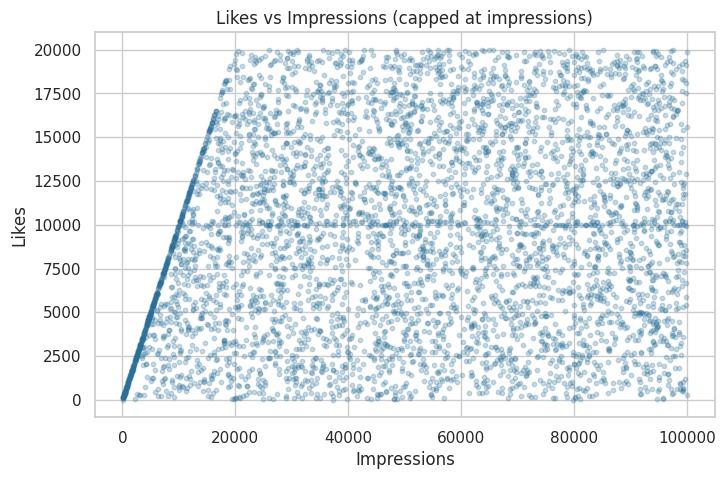

In [30]:
# 1. Scatter: likes vs impressions
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["impression_count"], df["likes"], alpha=0.25, s=10, color="#2a6f97")
ax.set_xlabel("Impressions"); ax.set_ylabel("Likes")
ax.set_title("Likes vs Impressions (capped at impressions)")
plt.show()

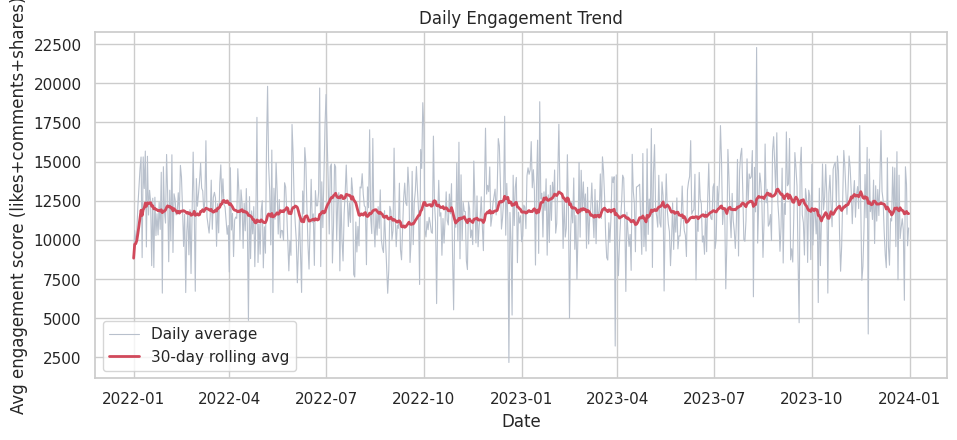

In [31]:
# 2. Line: daily engagement trend (30-day rolling average smooths the daily noise)
daily = df.groupby("posted_at")["engagement_score"].mean()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily.index, daily.values, color="#b8c0cc", lw=0.8, label="Daily average")
ax.plot(daily.index, daily.rolling(30, min_periods=1).mean(), color="#d1495b", lw=2, label="30-day rolling avg")
ax.set_xlabel("Date"); ax.set_ylabel("Avg engagement score (likes+comments+shares)")
ax.set_title("Daily Engagement Trend"); ax.legend()
plt.show()

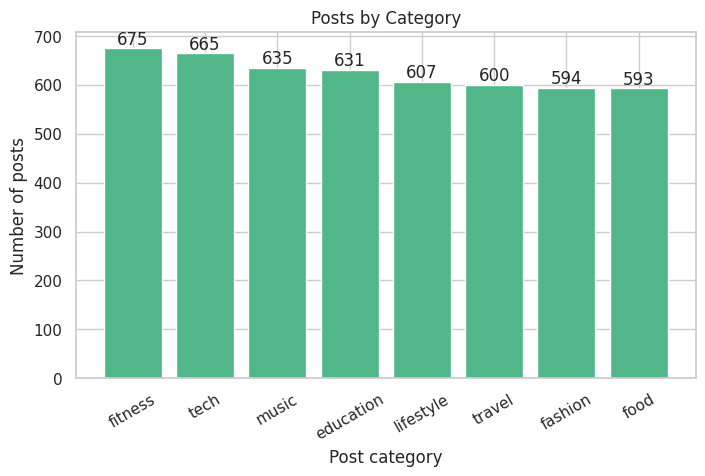

In [32]:
# 3. Bar: posts by category
counts = df["post_category"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index, counts.values, color="#52b788")
ax.bar_label(bars)
ax.set_xlabel("Post category"); ax.set_ylabel("Number of posts"); ax.set_title("Posts by Category")
plt.xticks(rotation=30)
plt.show()

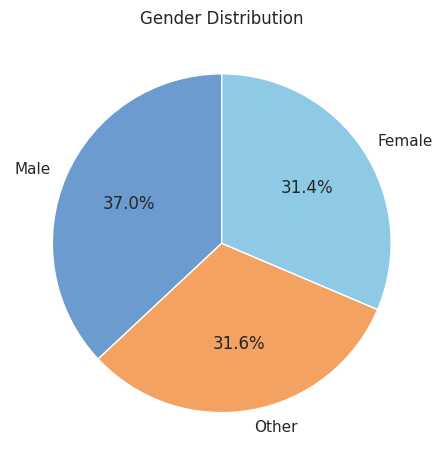

In [33]:
# 4. Pie: gender distribution
g = df["gender"].value_counts()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(g.values, labels=g.index, autopct="%1.1f%%", startangle=90,
       colors=["#6c9bcf", "#f4a261", "#8ecae6"], wedgeprops={"edgecolor": "white"})
ax.set_title("Gender Distribution")
plt.show()

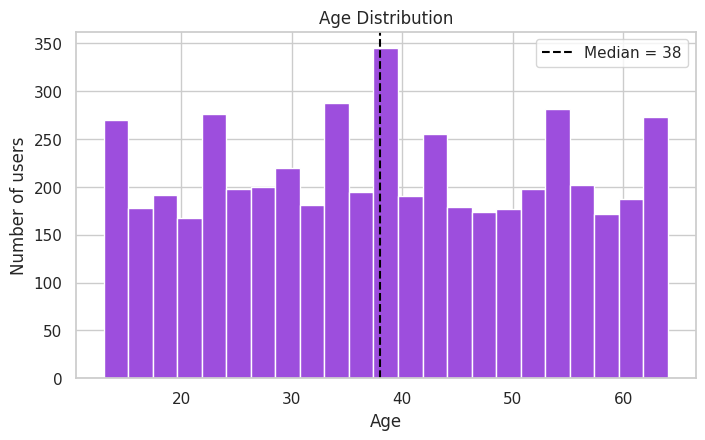

In [34]:
# 5. Histogram: age
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["age"], bins=23, color="#9d4edd", edgecolor="white")
ax.axvline(df["age"].median(), color="black", ls="--", label=f"Median = {df['age'].median():.0f}")
ax.set_xlabel("Age"); ax.set_ylabel("Number of users"); ax.set_title("Age Distribution"); ax.legend()
plt.show()

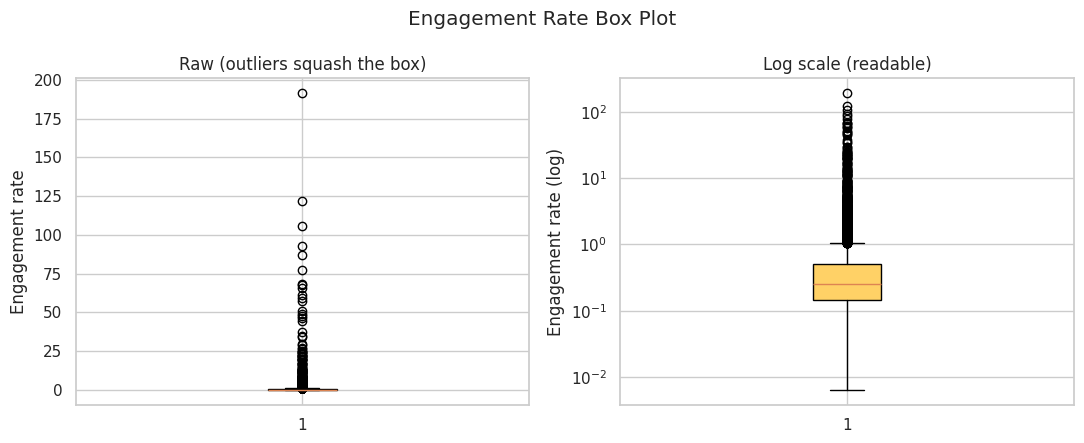

In [35]:
# 6. Box: engagement rate (log scale because of extreme outliers)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].boxplot(df["engagement_rate"], vert=True, patch_artist=True, boxprops=dict(facecolor="#ffd166"))
axes[0].set_title("Raw (outliers squash the box)"); axes[0].set_ylabel("Engagement rate")
axes[1].boxplot(df["engagement_rate"], vert=True, patch_artist=True, boxprops=dict(facecolor="#ffd166"))
axes[1].set_yscale("log"); axes[1].set_title("Log scale (readable)"); axes[1].set_ylabel("Engagement rate (log)")
fig.suptitle("Engagement Rate Box Plot")
plt.tight_layout(); plt.show()

### 6B. Seaborn

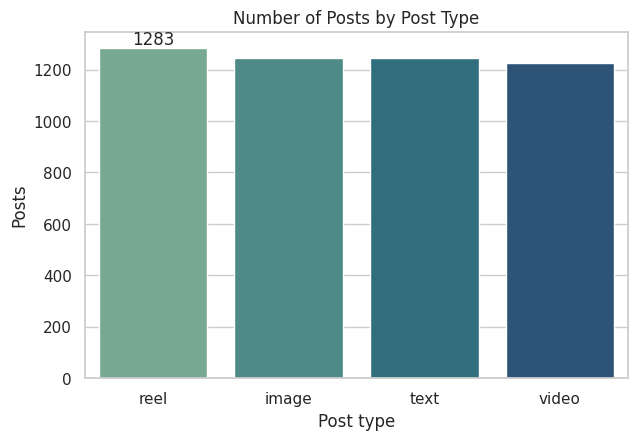

In [36]:
# 7. Count plot: post type
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(data=df, x="post_type", order=df["post_type"].value_counts().index, palette="crest", ax=ax)
ax.bar_label(ax.containers[0])
ax.set_title("Number of Posts by Post Type"); ax.set_xlabel("Post type"); ax.set_ylabel("Posts")
plt.show()

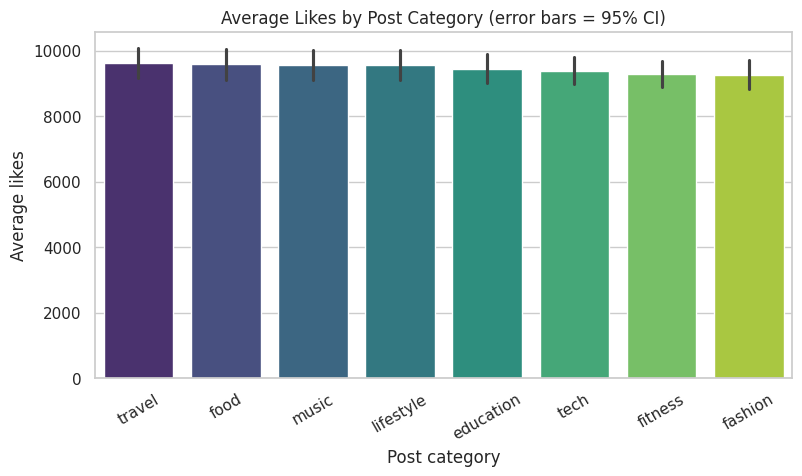

In [37]:
# 8. Bar plot: average likes by category
order = df.groupby("post_category")["likes"].mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=df, x="post_category", y="likes", order=order, palette="viridis", errorbar=("ci", 95), ax=ax)
ax.set_title("Average Likes by Post Category (error bars = 95% CI)")
ax.set_xlabel("Post category"); ax.set_ylabel("Average likes")
plt.xticks(rotation=30)
plt.show()

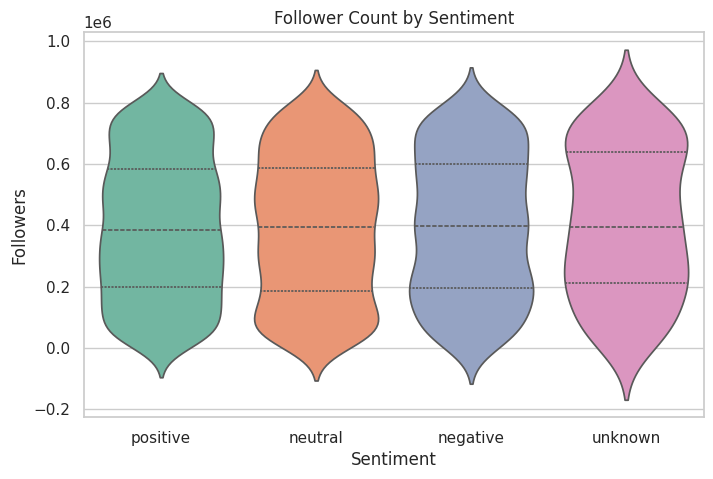

In [38]:
# 9. Violin: followers vs sentiment
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df, x="sentiment", y="follower_count", order=["positive", "neutral", "negative", "unknown"],
               palette="Set2", inner="quartile", ax=ax)
ax.set_title("Follower Count by Sentiment"); ax.set_xlabel("Sentiment"); ax.set_ylabel("Followers")
plt.show()

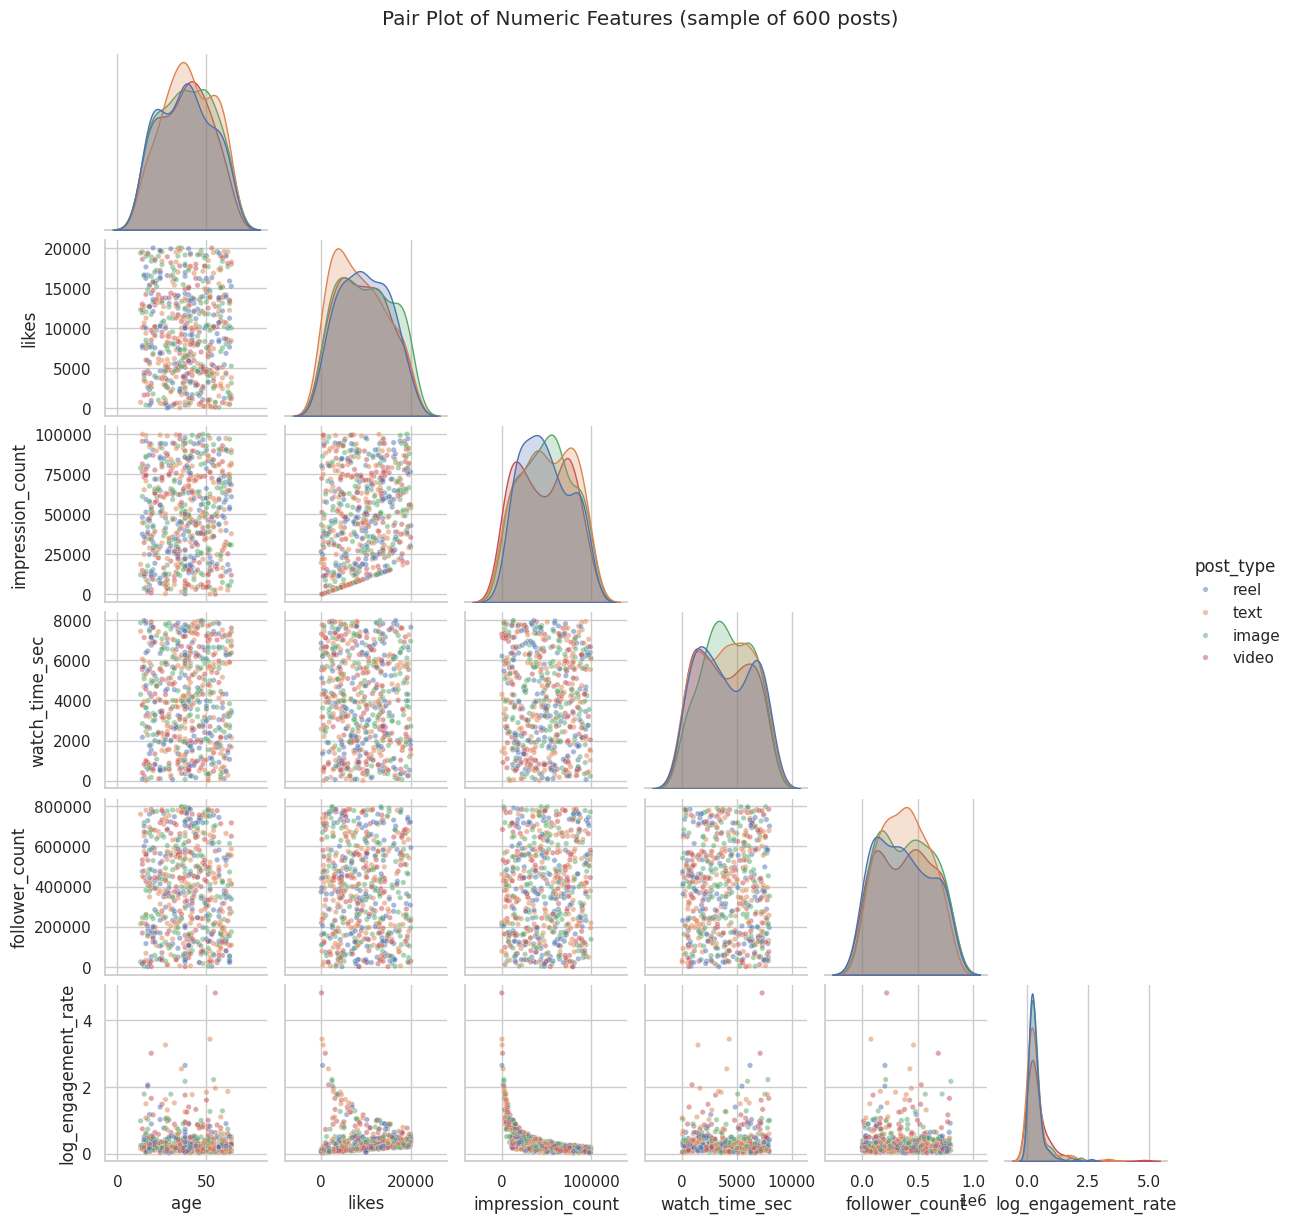

In [39]:
# 10. Pair plot: numeric features (random sample of 600 posts so it renders quickly)
cols = ["age", "likes", "impression_count", "watch_time_sec", "follower_count", "log_engagement_rate"]
pp = sns.pairplot(df.sample(600, random_state=42)[cols + ["post_type"]], hue="post_type",
                  corner=True, plot_kws={"alpha": 0.5, "s": 15}, height=2)
pp.figure.suptitle("Pair Plot of Numeric Features (sample of 600 posts)", y=1.02)
plt.show()

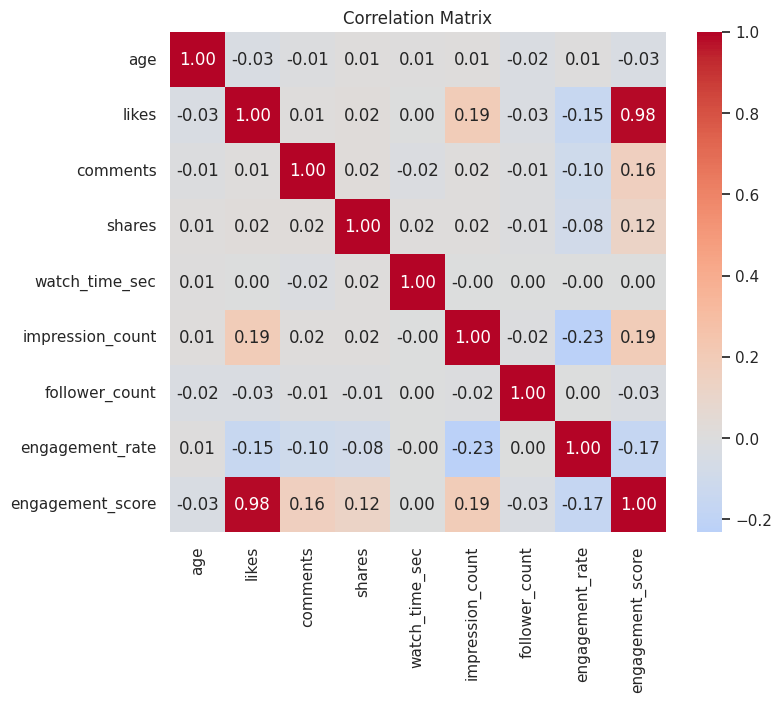

In [40]:
# 11. Heatmap: correlation matrix
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df[numeric_cols + ["engagement_score"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Matrix")
plt.show()

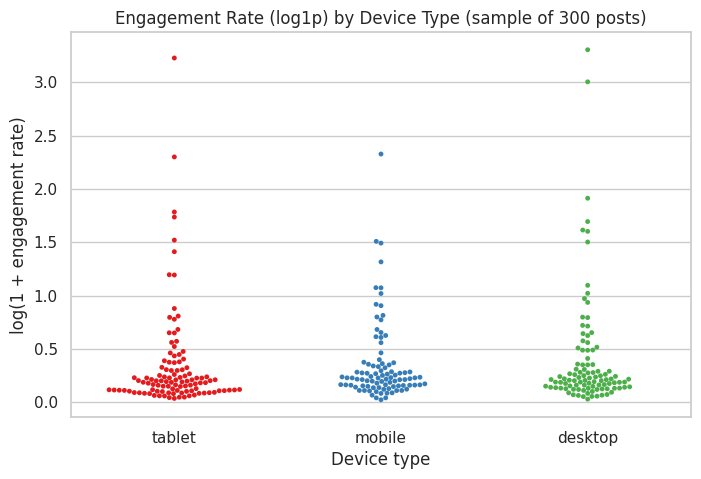

In [41]:
# 12. Swarm plot: engagement vs device (sample of 300 posts - swarm plots get unreadable with thousands of points)
s = df.sample(300, random_state=1)
fig, ax = plt.subplots(figsize=(8, 5))
sns.swarmplot(data=s, x="device_type", y="log_engagement_rate", palette="Set1", size=3.5, ax=ax)
ax.set_title("Engagement Rate (log1p) by Device Type (sample of 300 posts)")
ax.set_xlabel("Device type"); ax.set_ylabel("log(1 + engagement rate)")
plt.show()

### 6C. Plotly (interactive)

In [42]:
# 13. Interactive line: monthly trend of impressions and engagement score
monthly = df.groupby(df["posted_at"].dt.to_period("M").dt.to_timestamp()).agg(
    avg_engagement_score=("engagement_score", "mean"), avg_impressions=("impression_count", "mean")).reset_index()
fig = px.line(monthly, x="posted_at", y="avg_engagement_score", markers=True,
              title="Monthly Average Engagement Score",
              labels={"posted_at": "Month", "avg_engagement_score": "Avg engagement score"})
fig.show()

In [43]:
# 14. Interactive bar: median engagement rate by country
c = df.groupby("country")["engagement_rate"].median().sort_values(ascending=False).reset_index()
fig = px.bar(c, x="country", y="engagement_rate", color="engagement_rate", color_continuous_scale="Tealgrn",
             title="Median Engagement Rate by Country",
             labels={"engagement_rate": "Median engagement rate"})
fig.show()

In [44]:
# 15. Interactive bubble: category x post type, bubble size = number of posts
b = df.groupby(["post_category", "post_type"]).agg(
    posts=("post_id", "count"), avg_likes=("likes", "mean"), med_er=("engagement_rate", "median")).reset_index()
fig = px.scatter(b, x="avg_likes", y="med_er", size="posts", color="post_type", hover_name="post_category",
                 title="Category / Post-Type Performance (bubble = number of posts)",
                 labels={"avg_likes": "Average likes", "med_er": "Median engagement rate"})
fig.show()

In [45]:
# 16. Interactive scatter: impressions vs likes coloured by verified status
fig = px.scatter(df.sample(1500, random_state=3), x="impression_count", y="likes", color="is_verified",
                 opacity=0.6, hover_data=["country", "post_type", "post_category"],
                 title="Impressions vs Likes by Verified Status (sample of 1,500)")
fig.show()

In [46]:
# 17. Interactive heatmap: avg impressions by weekday and month
order_d = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pv = df.pivot_table(index="weekday", columns="month", values="impression_count", aggfunc="mean").reindex(order_d)
fig = px.imshow(pv, color_continuous_scale="YlGnBu", aspect="auto",
                title="Average Impressions by Weekday and Month",
                labels={"x": "Month", "y": "Weekday", "color": "Avg impressions"})
fig.show()

In [47]:
# 18. Interactive box: engagement rate by post type (log axis)
fig = px.box(df, x="post_type", y="engagement_rate", color="post_type", log_y=True,
             title="Engagement Rate by Post Type (log scale)")
fig.show()

### 7.1 Content performance

In [48]:
def rank(by, metric="engagement_rate"):
    t = df.groupby(by).agg(posts=("post_id", "count"),
                           median_er=("engagement_rate", "median"),
                           mean_er=("engagement_rate", "mean"),
                           avg_score=("engagement_score", "mean"),
                           avg_likes=("likes", "mean"))
    return t.sort_values("median_er", ascending=False)

print("POST TYPE"); display(rank("post_type"))
print("CATEGORY");  display(rank("post_category"))
print("COUNTRY");   display(rank("country"))

POST TYPE


,posts,median_er,mean_er,avg_score,avg_likes
post_type,,,,,
image,1247,0.26,0.90,"11,978.06","9,450.37"
text,1245,0.25,1.06,"11,901.91","9,412.96"
reel,1283,0.25,0.78,"11,981.17","9,509.55"
video,1225,0.25,1.12,"11,906.00","9,453.69"


CATEGORY


,posts,median_er,mean_er,avg_score,avg_likes
post_category,,,,,
education,631,0.28,0.84,"11,892.14","9,453.40"
fashion,594,0.26,0.81,"11,748.97","9,253.55"
music,635,0.26,0.89,"12,132.62","9,569.16"
food,593,0.25,1.36,"12,068.04","9,580.43"
travel,600,0.25,0.70,"12,059.14","9,615.63"
tech,665,0.25,1.16,"11,876.36","9,384.08"
lifestyle,607,0.25,1.09,"11,983.47","9,548.32"
fitness,675,0.25,0.87,"11,793.49","9,274.59"


COUNTRY


,posts,median_er,mean_er,avg_score,avg_likes
country,,,,,
UAE,503,0.27,1.11,"11,791.71","9,289.07"
Australia,493,0.27,1.32,"11,920.36","9,438.89"
Germany,490,0.27,0.76,"12,132.08","9,632.10"
Canada,513,0.26,0.92,"11,952.57","9,425.09"
Japan,472,0.26,0.77,"11,928.06","9,459.66"
Brazil,504,0.25,1.54,"11,775.51","9,302.21"
India,535,0.25,0.66,"12,020.29","9,505.21"
France,496,0.24,1.15,"12,071.76","9,569.47"
USA,501,0.24,0.58,"12,011.67","9,563.38"


### 7.2 User trends

In [49]:
print("AGE GROUP"); display(df.groupby("age_group").agg(posts=("post_id","count"), median_er=("engagement_rate","median"),
                                                          mean_er=("engagement_rate","mean"), avg_score=("engagement_score","mean")))
print("Correlation of age with engagement_rate / engagement_score:",
      round(df["age"].corr(df["engagement_rate"]), 3), "/", round(df["age"].corr(df["engagement_score"]), 3))
print("\nVERIFIED vs NOT VERIFIED"); display(df.groupby("is_verified").agg(posts=("post_id","count"), median_er=("engagement_rate","median"),
      mean_er=("engagement_rate","mean"), avg_score=("engagement_score","mean"), avg_followers=("follower_count","mean")))

AGE GROUP


,posts,median_er,mean_er,avg_score
age_group,,,,
18-24,636,0.27,1.04,"11,873.22"
25-34,977,0.25,0.81,"12,181.21"
35-44,1096,0.25,0.96,"12,000.38"
45-54,916,0.26,1.21,"11,836.46"
55-64,927,0.24,0.90,"11,593.24"


Correlation of age with engagement_rate / engagement_score: 0.008 / -0.031

VERIFIED vs NOT VERIFIED


,posts,median_er,mean_er,avg_score,avg_followers
is_verified,,,,,
False,4517,0.26,0.95,"11,987.57","395,042.84"
True,483,0.24,1.05,"11,518.38","381,123.45"


### 7.3 Behavioural insights

In [50]:
# The dataset only has a DATE (no clock time), so 'time of day' cannot be measured.
# I use the closest available time dimensions instead: weekday and month.
print("Does posted_at contain a time component?", (df["posted_at"].dt.hour != 0).any())

wd = df.groupby("weekday")["impression_count"].mean().reindex(order_d).round(0)
print("\nAvg impressions by weekday:\n", wd.to_string())
mo = df.groupby("month_name")["impression_count"].mean().sort_values(ascending=False).round(0)
print("\nTop 3 / bottom 3 months by avg impressions:\n", pd.concat([mo.head(3), mo.tail(3)]).to_string())
print("\nWeekday vs weekend avg impressions:\n", df.groupby("is_weekend")["impression_count"].mean().round(0).to_string())

Does posted_at contain a time component? False

Avg impressions by weekday:
 weekday
Monday      50,013.00
Tuesday     51,309.00
Wednesday   49,858.00
Thursday    48,119.00
Friday      49,431.00
Saturday    50,945.00
Sunday      50,346.00

Top 3 / bottom 3 months by avg impressions:
 month_name
September   51,514.00
February    51,146.00
August      51,000.00
January     49,407.00
July        48,923.00
June        48,134.00

Weekday vs weekend avg impressions:
 is_weekend
False   49,757.00
True    50,643.00


In [51]:
print("DEVICE TYPE vs WATCH TIME")
display(df.groupby("device_type")["watch_time_sec"].agg(["count", "mean", "median"]).round(0))

DEVICE TYPE vs WATCH TIME


,count,mean,median
device_type,,,
desktop,1658,"3,975.00","3,922.00"
mobile,1684,"4,088.00","4,111.00"
tablet,1658,"3,980.00","4,072.00"


### 7.4 Sentiment analysis

In [52]:
known = df[df["sentiment"] != "unknown"]
display(known.groupby("sentiment").agg(posts=("post_id","count"), median_er=("engagement_rate","median"), mean_er=("engagement_rate","mean"),
        avg_score=("engagement_score","mean"), avg_likes=("likes","mean"), avg_comments=("comments","mean"),
        avg_shares=("shares","mean"), avg_watch=("watch_time_sec","mean"), avg_impr=("impression_count","mean")))
print("Share of posts:\n", (known["sentiment"].value_counts(normalize=True)*100).round(1).to_string())

,posts,median_er,mean_er,avg_score,avg_likes,avg_comments,avg_shares,avg_watch,avg_impr
sentiment,,,,,,,,,
negative,960,0.26,1.04,"11,880.38","9,378.55","1,500.65","1,001.19","4,054.64","50,191.96"
neutral,1527,0.25,0.99,"11,793.40","9,288.01","1,516.01",989.38,"4,031.82","49,515.97"
positive,2363,0.26,0.95,"12,002.53","9,538.68","1,470.33",993.51,"3,980.73","49,986.16"


Share of posts:
 sentiment
positive   48.70
neutral    31.50
negative   19.80


In [53]:
# Which tests support (or not) these differences?
rows = []
for name, by, col, data in [("post_type -> engagement_rate", "post_type", "engagement_rate", df),
                            ("post_category -> engagement_rate", "post_category", "engagement_rate", df),
                            ("country -> engagement_rate", "country", "engagement_rate", df),
                            ("age_group -> engagement_rate", "age_group", "engagement_rate", df),
                            ("sentiment -> engagement_rate", "sentiment", "engagement_rate", known),
                            ("device -> watch_time_sec", "device_type", "watch_time_sec", df),
                            ("weekday -> impressions", "weekday", "impression_count", df)]:
    p = stats.kruskal(*[g[col].values for _, g in data.groupby(by)])[1]
    rows.append({"comparison": name, "p-value": round(p, 4), "significant at 5%?": "YES" if p < 0.05 else "no"})
u = stats.mannwhitneyu(df.loc[df.is_verified, "engagement_rate"], df.loc[~df.is_verified, "engagement_rate"])[1]
rows.append({"comparison": "verified vs not -> engagement_rate", "p-value": round(u, 4), "significant at 5%?": "YES" if u < 0.05 else "no"})
pd.DataFrame(rows)

,comparison,p-value,significant at 5%?
0,post_type -> engagement_rate,0.69,no
1,post_category -> engagement_rate,0.98,no
2,country -> engagement_rate,0.36,no
3,age_group -> engagement_rate,0.54,no
4,sentiment -> engagement_rate,0.99,no
5,device -> watch_time_sec,0.28,no
6,weekday -> impressions,0.46,no
7,verified vs not -> engagement_rate,0.09,no


## Final Insights & Summary

**Headline finding:** across every comparison asked for in the brief, the differences between groups are **small, and none is statistically significant** (all Kruskal-Wallis / Mann-Whitney p-values > 0.05, see the last table). Engagement in this dataset is essentially driven by individual-post variation, not by post type, category, country, age, device or sentiment. The "winners" below are the numerically highest groups, not proven drivers.

### Content performance
| Question | Answer | Evidence |
|---|---|---|
| Post type with highest engagement | **Reel** by average interactions (11,981 likes+comments+shares per post), with **image** a near tie (11,978) and highest median engagement rate (0.26) | Spread across the four types is under 1 % (p = 0.69) |
| Best content category | **Music** has the most interactions per post (12,133); **education** has the highest median engagement rate (0.28) | Food looks best on *mean* rate (1.36) only because of a few extreme outlier posts. Categories are statistically indistinguishable (p = 0.98) |
| Country with highest avg engagement rate | **UAE, Australia and Germany tie** at a median of 0.27 (USA, UK, France lowest at 0.24). Brazil has the highest *mean* (1.54), again driven by outliers | Gap between best and worst is 0.03 points (p = 0.36) |

### User trends
- **Age:** no meaningful effect. Age vs engagement rate correlation = 0.01 and vs interactions = −0.03. 18-24 has the highest median rate (0.27) and 55-64 the lowest (0.24); 25-34 has the most interactions per post (12,181). Differences are not significant (p = 0.54).
- **Verified accounts:** only 9.7 % of posts (483). Verified posts get *slightly fewer* interactions (11,518 vs 11,988) and a slightly lower median rate (0.24 vs 0.26), but a slightly higher mean rate (1.05 vs 0.95). The mixed direction and p = 0.09 mean there is **no reliable verified-account advantage**. Verified users also have no more followers on average (381k vs 395k).

### Behavioural insights
- **Best time of day:** *cannot be answered* - `posted_at` has only a date, no clock time. As the closest proxy, **Tuesday** has the highest average impressions (51,309) and **Thursday** the lowest (48,119); by month, **September** is highest. These gaps are ≈ 6 % at most and not significant (p = 0.46). If time-of-day matters to the business, hour-level timestamps need to be collected.
- **Device vs watch time:** **mobile** has the highest average watch time (4,088 s) vs desktop 3,975 s and tablet 3,980 s - about 3 % higher, not significant (p = 0.28).

### Sentiment
- **Best sentiment:** **positive** posts lead on average interactions (12,003) and likes (9,539) and are the largest group (48.7 % of labelled posts); positive and negative tie on median engagement rate (0.26).
- **Negative posts (19.8 %)** are competitive, not weaker: the highest mean engagement rate (1.04) and the most shares per post (1,001). **Neutral posts (31.5 %)** are the lowest performers on interactions (11,793) and likes (9,288), i.e. content that triggers no strong reaction travels least. None of these gaps is significant (p = 0.99 for engagement rate).

### Data-quality notes & recommendations
1. 3 % of rows were missing in six columns (imputed); 467 rows had likes/comments/shares above impressions (capped & flagged); no full duplicates (9 repeated `post_id`s were kept, they are different posts).
2. `engagement_rate` is extremely skewed (max 191, median 0.25) - always report the **median** or a winsorised version.
3. Because the metrics look uniformly distributed and uncorrelated, this dataset appears to be synthetic/randomly generated. In real data I would expect clearer separation between post types and categories.
4. **Recommendations:** (a) do not shift strategy on these small gaps; run controlled A/B tests per post type first; (b) capture hour-level posting time; (c) investigate the low-impression posts with engagement rates above 10 (68 posts), which are the real outliers.